In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/SP9144/FMML_Data/main/Automobile_data.csv"
data = pd.read_csv(url)

data.replace("?", np.nan, inplace=True)
data = data.dropna().copy()

data["price"] = pd.to_numeric(data["price"])
data["horsepower"] = pd.to_numeric(data["horsepower"])
data["highway-mpg"] = pd.to_numeric(data["highway-mpg"])

X = data.drop("price", axis=1)
y = data["price"]

print("Number of data points:", len(data))
display(data.head())

Number of data points: 159


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450
6,1,158,audi,gas,std,four,sedan,fwd,front,105.8,...,136,mpfi,3.19,3.4,8.5,110,5500,19,25,17710
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.8,...,131,mpfi,3.13,3.4,8.3,140,5500,17,20,23875
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,...,108,mpfi,3.5,2.8,8.8,101,5800,23,29,16430


Correlation with price:


,Correlation
highway-mpg,-0.720090
city-mpg,-0.692273
symboling,-0.162794
compression-ratio,0.209361
height,0.244836
wheel-base,0.734419
horsepower,0.759874
length,0.760952
engine-size,0.841496
width,0.843371


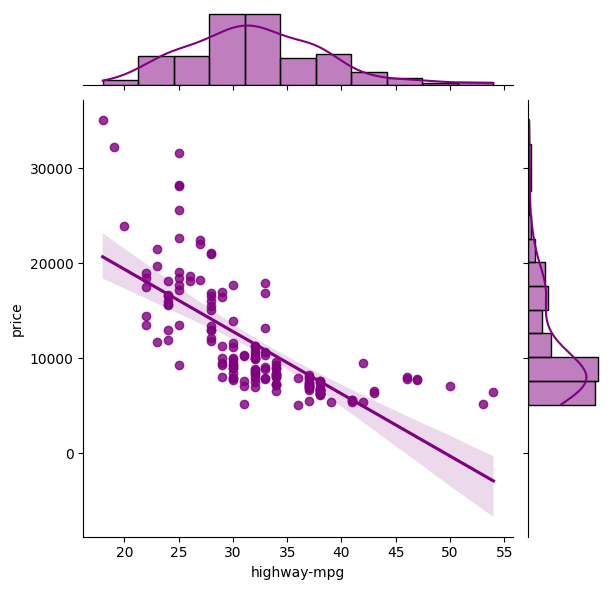

Correlation between highway-mpg and price: -0.72


In [2]:
numeric_features = [
    "symboling", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-size", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg"
]

correlations = data[numeric_features + ["price"]].corr(numeric_only=True)["price"]
correlations = correlations.drop("price").sort_values()

print("Correlation with price:")
display(correlations.to_frame("Correlation"))

feature = "highway-mpg"

sns.jointplot(
    data=data,
    x=feature,
    y="price",
    kind="reg",
    color="purple"
)
plt.show()

print("Correlation between", feature, "and price:",
      round(data[feature].corr(data["price"]), 3))

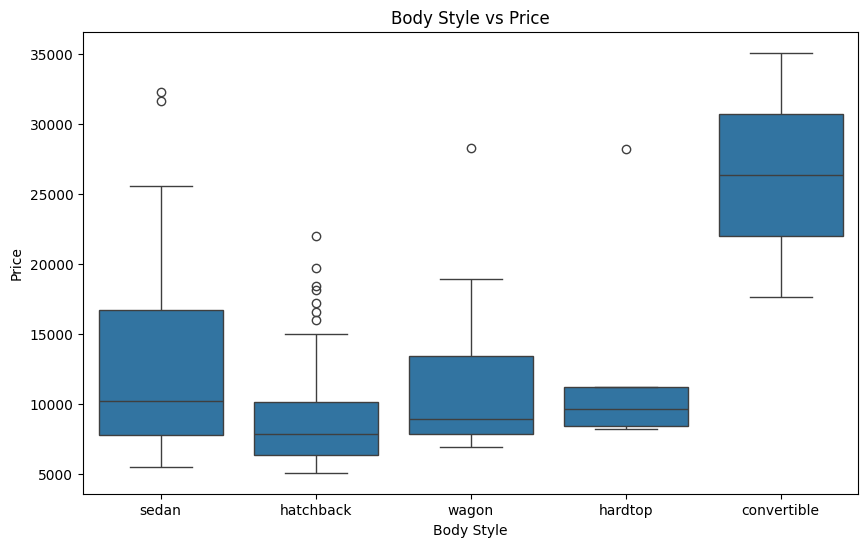

Median price by body style:


,Median Price
body-style,
convertible,26362.5
sedan,10245.0
hardtop,9639.0
wagon,8921.0
hatchback,7847.0


Highest median price body style: convertible


In [3]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x="body-style", y="price")
plt.title("Body Style vs Price")
plt.xlabel("Body Style")
plt.ylabel("Price")
plt.show()

median_prices = data.groupby("body-style")["price"].median().sort_values(
    ascending=False
)

print("Median price by body style:")
display(median_prices.to_frame("Median Price"))

print("Highest median price body style:", median_prices.index[0])

1. Which body type has the highest median price? Which appears costliest overall?
The body type with the highest median price is identified by the box plot and the median-price table above. The overall costliest body style should be assessed by considering its price distribution, not just a single expensive car.

2. Is the maximum value a good way to determine the costliest body style? Why is the interquartile range better?
No. The maximum value may be an outlier and may not represent the typical price of a body style. The interquartile range (IQR), represented by the box, shows the middle 50% of prices. The median and IQR provide a more reliable comparison of typical prices and variability.

3. Could body style be a good predictor of price? Why?
Yes, body style could be a useful predictor because different body styles may have different median prices and price distributions. However, it is not sufficient on its own, since price can also depend on features such as horsepower, engine size, manufacturer and vehicle weight.

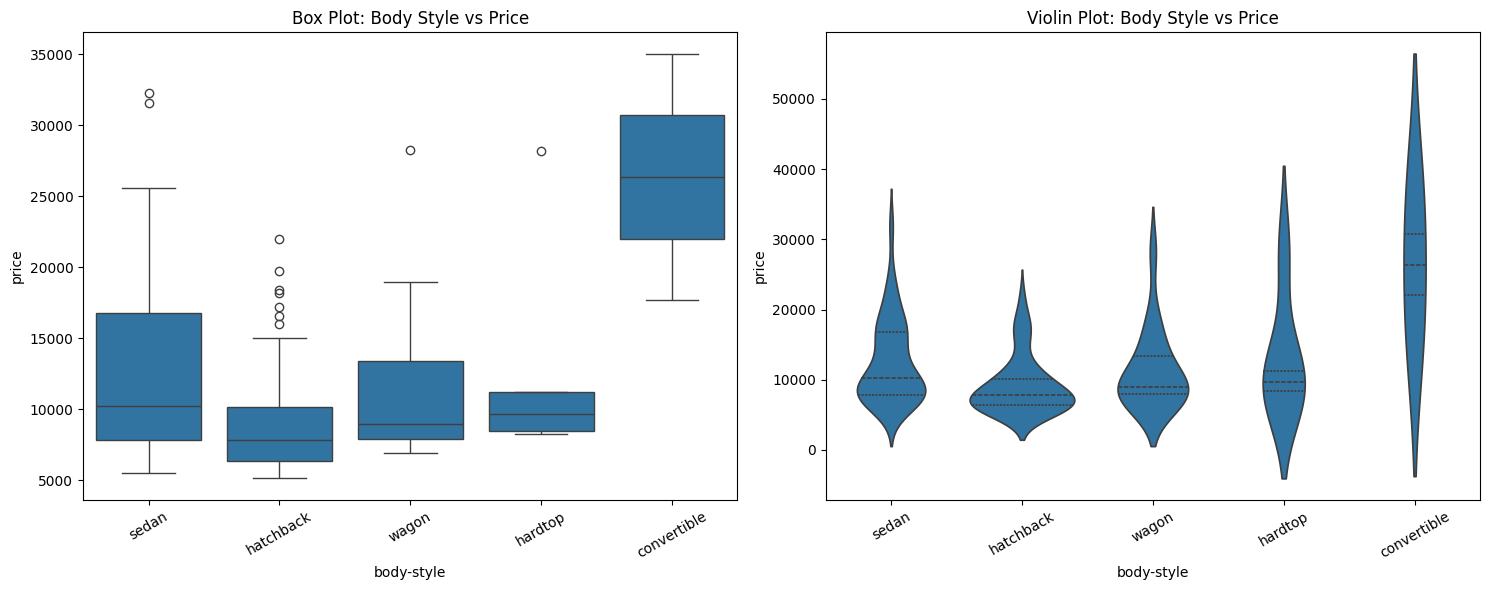

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(
    data=data,
    x="body-style",
    y="price",
    ax=axes[0]
)
axes[0].set_title("Box Plot: Body Style vs Price")
axes[0].tick_params(axis="x", rotation=30)

sns.violinplot(
    data=data,
    x="body-style",
    y="price",
    ax=axes[1],
    inner="quartile"
)
axes[1].set_title("Violin Plot: Body Style vs Price")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

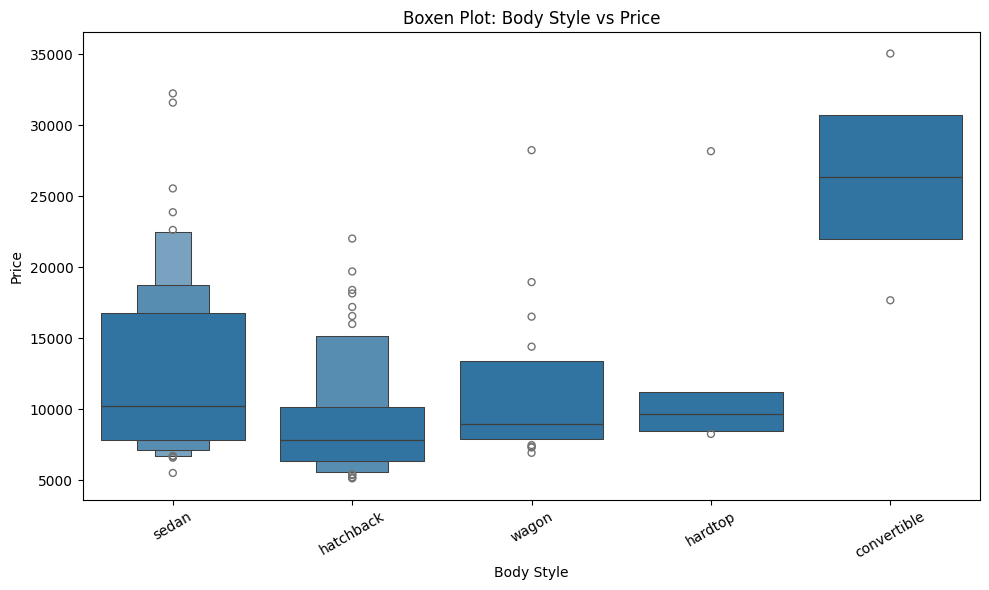

In [5]:
plt.figure(figsize=(10, 6))

sns.boxenplot(
    data=data,
    x="body-style",
    y="price"
)

plt.title("Boxen Plot: Body Style vs Price")
plt.xlabel("Body Style")
plt.ylabel("Price")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

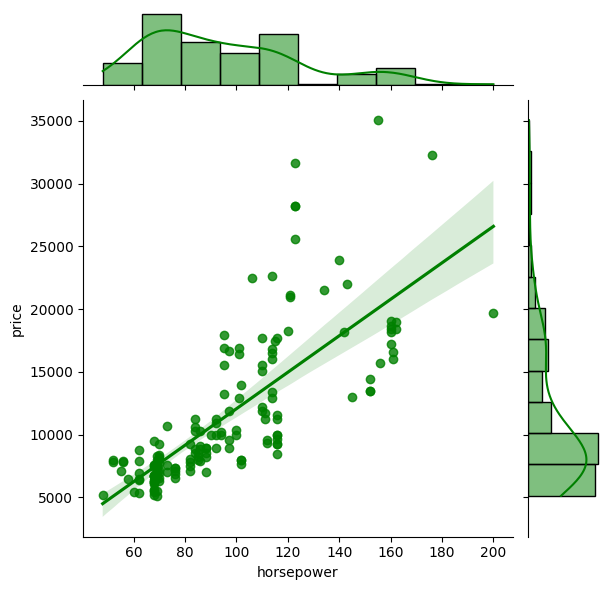

Horsepower-price correlation: 0.76


In [6]:
sns.jointplot(
    data=data,
    x="horsepower",
    y="price",
    kind="reg",
    color="green"
)
plt.show()

print("Horsepower-price correlation:",
      round(data["horsepower"].corr(data["price"]), 3))